In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
df = pd.read_csv("26-customer_data.csv")

In [3]:
df.head()

,Annual_Income,Spending_Score
0,-5.772478,-4.818216
1,6.768246,-5.424570
2,5.796159,-6.239967
3,7.096022,-5.272612
4,-5.725561,-9.316889


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1499 entries, 0 to 1498
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Annual_Income   1499 non-null   float64
 1   Spending_Score  1499 non-null   float64
dtypes: float64(2)
memory usage: 23.6 KB


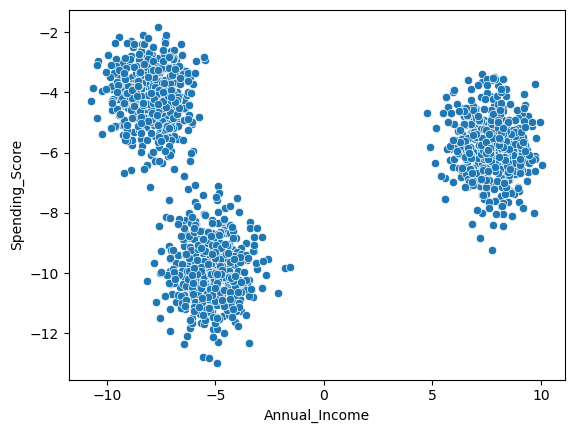

In [6]:
sns.scatterplot(data=df, x="Annual_Income", y="Spending_Score")
plt.show()

In [7]:
from sklearn.model_selection import train_test_split

In [9]:
X_train, X_test = train_test_split(df, test_size=0.2, random_state=15)

In [10]:
X_train

,Annual_Income,Spending_Score
258,7.809992,-5.031123
195,7.769519,-6.059915
817,-8.529586,-4.853877
820,-5.765759,-9.822013
716,-7.932068,-4.882406
...,...,...
667,-6.734875,-5.107626
156,-8.236823,-3.127431
384,-7.744180,-3.563590
645,-6.151325,-9.263209


In [11]:
X_test

,Annual_Income,Spending_Score
513,-5.172436,-11.041683
906,-7.281623,-4.334985
1366,-7.933360,-4.679263
367,7.247201,-4.157474
1392,-5.963997,-9.834777
...,...,...
879,-4.747040,-9.904793
722,-4.886108,-10.754440
557,7.764069,-4.766483
1230,-5.160849,-10.713683


In [13]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_t"rain)
X_test_scaled = scaler.transform(X_test)

In [15]:
from sklearn.cluster import KMeans

In [23]:
# Elbow method
wcss = []


for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, init="k-means++")
    kmeans.fit(X_train_scaled)
    wcss.append(kmeans.inertia_)

In [20]:
kmeans.labels_ # -> rowlara atanan cluster numaralari.

array([9, 3, 8, ..., 1, 2, 7], dtype=int32)

In [22]:
kmeans.inertia_ # -> wcss lerin hesaplanmis hali.(butun noktalarin kendi olusturdugu centroitten uzakliklarin toplami.)

4.028216770173519

In [24]:
wcss

[196.92068784710153,
 68.44836482219307,
 11.697030239519934,
 9.905008948675164,
 7.881700552730018,
 7.4150860466387005,
 5.539634355084944,
 4.987653009814116,
 4.400178826738768,
 4.056021033342977]

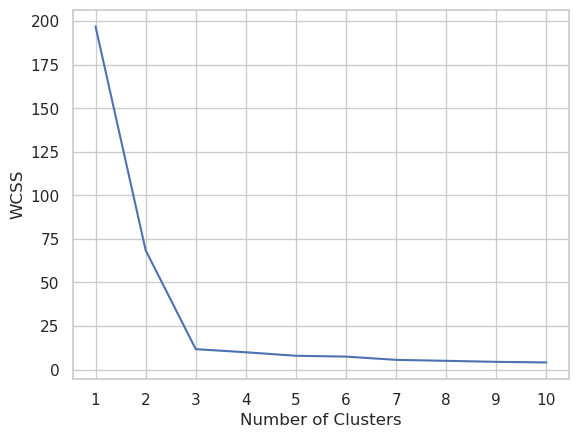

In [34]:
sns.set_theme(style=("whitegrid"))
plt.plot(range(1,11), wcss)
plt.xticks(range(1,11))
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.show()

In [36]:
kmeans = KMeans(n_clusters=3)

kmeans.fit(X_train_scaled)

KMeans(n_clusters=3)

In [38]:
y_pred = kmeans.predict(X_test_scaled)

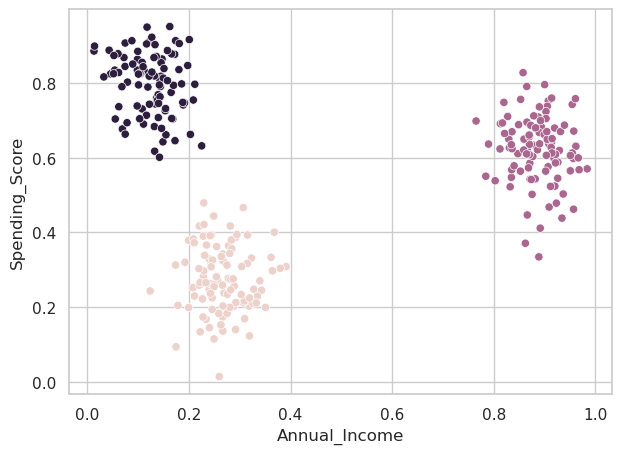

In [49]:
plt.figure(figsize=(7,5))
sns.scatterplot(data=pd.DataFrame(X_test_scaled, columns=X_test.columns), x="Annual_Income", y="Spending_Score", hue=y_pred, legend=False)
plt.show()

In [50]:
############################################################################################################################################

In [51]:
!pip install kneed

In [54]:
from kneed import KneeLocator # wcss yine hesapladiktan sonra wcss kneelocatora veriyoruz.
                              # (kacincida kirildigini matematiksel olarak hesaplayip gosteriyor)

In [60]:
kl = KneeLocator(range(1,11), wcss, curve="convex", direction="decreasing")

In [61]:
kl.elbow

np.int64(3)

In [62]:
# silhoutte score

In [63]:
from sklearn.metrics import silhouette_score

In [68]:
silhoutte_scores = [] # silhoutte scorelarda en az 2 k=cluster yapmamiz gerekiyor.
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, init="k-means++")
    kmeans.fit(X_train_scaled)
    score = silhouette_score(X_train_scaled, kmeans.labels_)
    silhoutte_scores.append(score)  

In [69]:
silhoutte_scores # en yulsek scor hangisi ise onu almaliyiz.

[np.float64(0.6538372460771634),
 np.float64(0.7856941696336582),
 np.float64(0.6447386165583312),
 np.float64(0.5379176436475993),
 np.float64(0.48692431561428795),
 np.float64(0.379828472084039),
 np.float64(0.37335187095996913),
 np.float64(0.36037897955942505),
 np.float64(0.3464492473950443)]

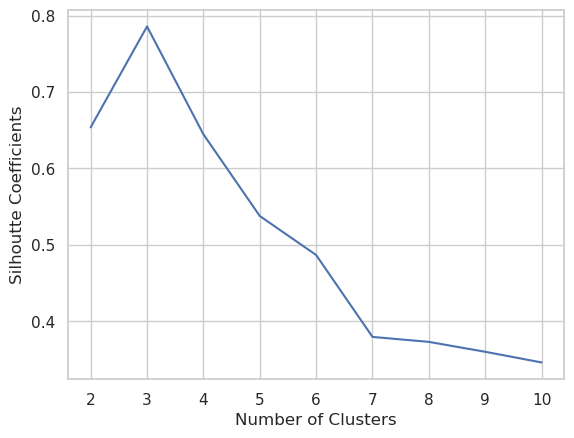

In [71]:
sns.set_theme(style=("whitegrid"))
plt.plot(range(2,11), silhoutte_scores)
plt.xticks(range(2,11))
plt.xlabel("Number of Clusters")
plt.ylabel("Silhoutte Coefficients")
plt.show()